# Project 1: Wealth Inequality in Denmark
Starter notebook. Add your names, code and interpretations. Keep your simulation module (.py) beside this notebook.

**Group name:**  
**Members:**

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [1]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


## 1.1   Download and Read the Tables
Tasks and hints: PDF Section 1.1.

In [ ]:

# 1.1 Downloading and reading the tables

# FORMUE16
print("FORMUE16:")
display(percentiles.head())

# Inspect age groups and percentile codes
print("Age groups:", percentiles["ALDER"].unique())
print("Percentiles:", percentiles["PERCENTIL"].unique())

# Inspect FORMUE15 table information to identify variable codes
url = "https://api.statbank.dk/v1/tableinfo/FORMUE15"
table_info = requests.get(url, params={"lang": "en", "format": "JSON"})
table_info.raise_for_status()

for variable in table_info.json()["variables"]:
    print(variable["id"], ":", variable["text"])
    print("Values:", [(v["id"], v["text"]) for v in variable["values"][:10]])
    print()


FORMUE16:


,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-872193
1,P1,006,1829,2024,-474253
2,P1,006,3039,2024,-1184850
3,P1,006,4049,2024,-1212373
4,P1,006,5059,2024,-1007915


Age groups: <ArrowStringArray>
['1802', '1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
Length: 9, dtype: str
Percentiles: <ArrowStringArray>
[ 'P1',  'P2',  'P3',  'P4',  'P5',  'P6',  'P7',  'P8',  'P9', 'P10', 'P11',
 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P20', 'P21', 'P22',
 'P23', 'P24', 'P25', 'P26', 'P27', 'P28', 'P29', 'P30', 'P31', 'P32', 'P33',
 'P34', 'P35', 'P36', 'P37', 'P38', 'P39', 'P40', 'P41', 'P42', 'P43', 'P44',
 'P45', 'P46', 'P47', 'P48', 'P49', 'P50', 'P51', 'P52', 'P53', 'P54', 'P55',
 'P56', 'P57', 'P58', 'P59', 'P60', 'P61', 'P62', 'P63', 'P64', 'P65', 'P66',
 'P67', 'P68', 'P69', 'P70', 'P71', 'P72', 'P73', 'P74', 'P75', 'P76', 'P77',
 'P78', 'P79', 'P80', 'P81', 'P82', 'P83', 'P84', 'P85', 'P86', 'P87', 'P88',
 'P89', 'P90', 'P91', 'P92', 'P93', 'P94', 'P95', 'P96', 'P97', 'P98', 'P99']
Length: 99, dtype: str
FORMUE : wealth
Values: [('0000M10', 'Under (-1.000.000 DKK)'), ('M100M05', '(-1.000.000 DKK) - (-500.000 DKK)'), ('M

The aggregate age category for 18 years old and over is '1802'.
The FORMUE16 dataset contains 99 wealth percentiles for each age category. For the following analysis we contiue by excluding the adult category from the age-specific data and retain the eight individual age groups. 

In [6]:
# 1.1 Download and Read the Tables

# Download FORMUE15: Wealth brackets and population counts
counts = download(
    'FORMUE15',
    FORMUE='*',
    DEFINITION='D20',
    PRISENHED='006',
    ALDER='*',
    Tid='2024'
)

# Inspect the first rows
display(counts.head())

# Separate all adults from the eight age groups
percentiles_all = percentiles[percentiles['ALDER'] == '1802'].copy()
percentiles_age = percentiles[percentiles['ALDER'] != '1802'].copy()

counts_all = counts[counts['ALDER'] == '1802'].copy()
counts_age = counts[counts['ALDER'] != '1802'].copy()

# Check the number of age groups
print("Age groups in FORMUE16:", percentiles_age['ALDER'].nunique())
print("Age groups in FORMUE15:", counts_age['ALDER'].nunique())

# Inspect the wealth brackets
print("Wealth brackets:", counts['FORMUE'].unique())


,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,39466
1,0000M10,D20,006,1829,2024,2345
2,0000M10,D20,006,3039,2024,11605
3,0000M10,D20,006,4049,2024,9680
4,0000M10,D20,006,5059,2024,8096


Age groups in FORMUE16: 8
Age groups in FORMUE15: 8
Wealth brackets: <ArrowStringArray>
['0000M10', 'M100M05', 'M050000', '0000005', '0050010', '0100015', '0150020',
 '0200025', '0250030', '0300035', '0350040', '0400045', '0450050', '0500055',
 '0550060', '0600000']
Length: 16, dtype: str


## 1.2   Plot the Age Profiles
Tasks and hints: PDF Section 1.2.

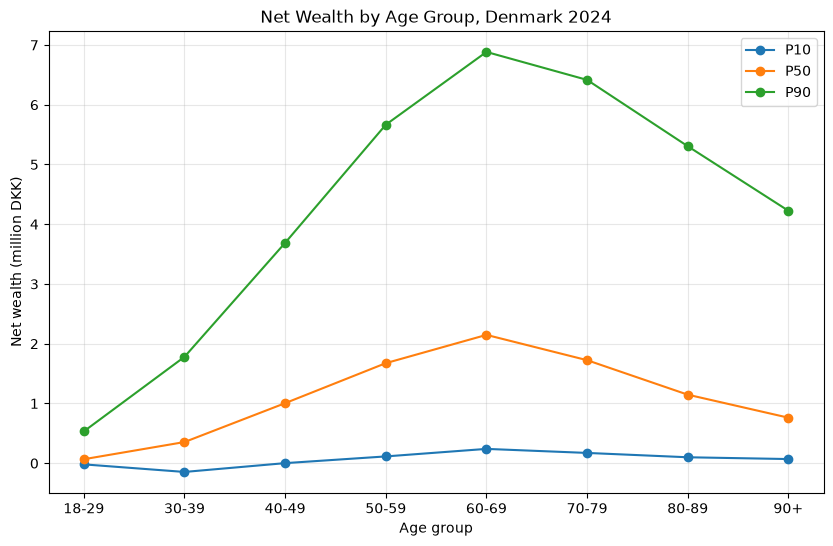

percentile,P10,P50,P90,Upper gap,Lower gap
ALDER,,,,,
18-29,-19750.0,66507.0,532429.0,465922.0,86257.0
30-39,-146586.0,353896.0,1780078.0,1426182.0,500482.0
40-49,912.0,1004750.0,3688269.0,2683519.0,1003838.0
50-59,113324.0,1674287.0,5665305.0,3991018.0,1560963.0
60-69,239280.0,2147564.0,6883537.0,4735973.0,1908284.0
70-79,171695.0,1724056.0,6415595.0,4691539.0,1552361.0
80-89,99096.0,1146853.0,5305568.0,4158715.0,1047757.0
90+,69252.0,761637.0,4225415.0,3463778.0,692385.0


percentile,10,50,90,upper_gap,lower_gap
ALDER,,,,,
1829,-19750.0,66507.0,532429.0,465922.0,86257.0
3039,-146586.0,353896.0,1780078.0,1426182.0,500482.0
4049,912.0,1004750.0,3688269.0,2683519.0,1003838.0
5059,113324.0,1674287.0,5665305.0,3991018.0,1560963.0
6069,239280.0,2147564.0,6883537.0,4735973.0,1908284.0
7079,171695.0,1724056.0,6415595.0,4691539.0,1552361.0
8089,99096.0,1146853.0,5305568.0,4158715.0,1047757.0
9099,69252.0,761637.0,4225415.0,3463778.0,692385.0


Widest upper gap: 6069
Amount: 4,735,973 DKK
Age groups with negative P10:
['1829', '3039']


In [10]:

# 1.2 Plot the Age Profiles

# Convert percentile codes from strings to integers
percentiles_age["percentile"] = (
    percentiles_age["PERCENTIL"].str.replace("P", "").astype(int)
)

# Reshape data: one row per age group and one column per percentile
wealth_age = percentiles_age.pivot_table(
    index="ALDER",
    columns="percentile",
    values="value"
)

# Select P10, P50 and P90
wealth_profile = wealth_age[[10, 50, 90]].copy()

# Define age group labels
age_labels = ["18-29", "30-39", "40-49", "50-59",
              "60-69", "70-79", "80-89", "90+"]

# Plot the age profiles
fig, ax = plt.subplots(figsize=(10, 6))

for p in [10, 50, 90]:
    ax.plot(
        age_labels,
        wealth_profile[p] / 1_000_000,
        marker="o",
        label=f"P{p}"
    )

ax.set_xlabel("Age group")
ax.set_ylabel("Net wealth (million DKK)")
ax.set_title("Net Wealth by Age Group, Denmark 2024")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

# Calculate upper and lower wealth gaps
wealth_profile["upper_gap"] = wealth_profile[90] - wealth_profile[50]
wealth_profile["lower_gap"] = wealth_profile[50] - wealth_profile[10]


# Display results with readable age labels
age_names = {
    "1829": "18-29",
    "3039": "30-39",
    "4049": "40-49",
    "5059": "50-59",
    "6069": "60-69",
    "7079": "70-79",
    "8089": "80-89",
    "9099": "90+"
}

wealth_profile_display = wealth_profile.rename(index=age_names)

display(
    wealth_profile_display.rename(columns={
        10: "P10",
        50: "P50",
        90: "P90",
        "upper_gap": "Upper gap",
        "lower_gap": "Lower gap"
    }).round(0)
)

display(wealth_profile)

# Find the age group with the widest upper gap
max_age = wealth_profile["upper_gap"].idxmax()
max_gap = wealth_profile.loc[max_age, "upper_gap"]

print(f"Widest upper gap: {max_age}")
print(f"Amount: {max_gap:,.0f} DKK")

# Identify age groups with negative P10
negative_p10 = wealth_profile[wealth_profile[10] < 0]

print("Age groups with negative P10:")
print(negative_p10.index.tolist())


**Interpretation.** Write your answer here.

## 1.3   Who Has Negative Net Wealth?
Tasks and hints: PDF Section 1.3.

**Interpretation.** Write your answer here.

## 2.1   Give Everybody Their Age-Group Median
Tasks and hints: PDF Section 2.1.

In [11]:
# Write your simulation function in a .py file next to this notebook and import it here.

**Interpretation.** Write your answer here.

## 2.2   Allow Wealth to Vary Within Each Age Group
Tasks and hints: PDF Section 2.2.

## 2.3   Compare Both Economies with Denmark
Tasks and hints: PDF Section 2.3.

**Interpretation.** Write your answer here.

## 2.4   An Older Denmark
Tasks and hints: PDF Section 2.4.

**Interpretation.** Write your answer here.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).